# Initialization

In [1]:
# 1. Importing packages
from nest import cell, layers, properties, boundary, degradation

# 2. Define Species and Mixture
fuel_mix = properties.Mixture((properties.BasicSpecies.H2, properties.BasicSpecies.H2O))
air_mix = properties.Mixture((properties.BasicSpecies.O2, properties.BasicSpecies.N2))

# 3. Define cell Layers with their properties (kinetic, transport, conductivity, etc.)
Ni_YSZ = layers.Layer(
    delta=1000e-6 + 10e-6,
    kinetic=layers.ButlerVolmer(
        fuel_mix,
        nu=[-1, 1],
        n_e=2,
        alpha=0.59,
        beta=1 - 0.59,
        gamma=1.82527e6,
        p=[-0.1, 0.33],
        theta=1,
        E_act=1.09 / 8.617333262e-5 * 8.314510,
    ),
    transport=layers.BinaryFick(
        dp=600e-9,
        epsilon=0.3,
        tau=2,
    ),
)
YSZ = layers.Layer(
    delta=8e-6 - 1.5e-6,
    conductivity=layers.Conductivity(
        sigma0=3.6e7,
        E_act=8e4,
    ),
)
YSZ_CGO = layers.Layer(
    delta=3e-6,
    conductivity=layers.Conductivity(sigma0=1715, E_act=8785 * 8.314510, theta=0),
)
CGO = layers.Layer(
    delta=5e-6 - 1.5e-6,
    conductivity=layers.Conductivity(
        sigma0=1.09e7,
        E_act=0.64 / 8.617333262e-5 * 8.314510,
    ),
)
LSCF_CGO = layers.Layer(
    delta=32e-6,
    kinetic=layers.ButlerVolmer(
        air_mix,
        alpha=0.65,
        beta=1 - 0.65,
        gamma=1.51556e8,
        nu=[-0.5, 0.0],
        E_act=1.45 / 8.617333262e-5 * 8.314510,
        p=[0.22, 0.0],
    ),
    transport=layers.BinaryFick(dp=6e-7, epsilon=0.3, tau=2.8),
)

# 4. Define cell from the layers
cellModel = cell.Cell(16e-4, Ni_YSZ, (YSZ, YSZ_CGO, CGO), LSCF_CGO)

# 5. Define boundary conditions
n_fuel = 8.23e-05  # mol/s
n_air = 0.000345476  # mol/s
x_H2 = 0.94
x_O2 = 0.21
conditions = boundary.BoundaryData(
    V=0.7,
    j=0.7e4,
    n_fuel=[n_fuel * x_H2, n_fuel * (1 - x_H2)],
    n_air=[n_air * x_O2, n_air * (1 - x_O2)],
    T=700 + 273.15,
    P=1e5,
)

# 6. Defining Cr poisoning model
Cr_poisoning = degradation.ChromiumPoison(
    x_H2O=0.01,
    j0=4.27254e7,
    E_act=1.45 / 8.617333262e-5 * 8.314510,
)

# Updating the air electrode layer with the degradation model
LSCF_CGO.degradation = Cr_poisoning

# 7. Defining Ni agglomeration model
Ni_agglomeration = degradation.NickelAgglomeration(
    # Material properties
    psi_ed=0.4,
    psi_el=0.6,
    r0_ed=300e-9,
    r0_el=300e-9,
    epsilon=0.3,
    # Fitting parameters
    alpha=3.04e8,
    E_act=242e3,
    r_ed_max=500e-9,
)

# Updating the fuel electrode layer with the degradation model
Ni_YSZ.degradation = Ni_agglomeration
# Normalizing the kinetic pre-factor to the initial conditions
Ni_YSZ.kinetic.gamma = 1.82527e6 / 4.19e12  # gamma/lambda_ref

CrScale = layers.Layer(
    delta=0,
    conductivity=layers.Conductivity(sigma0=45.8, E_act=33.3e3, theta=0),
    degradation=degradation.InterconnectOxidation(k_mg=0.02361, E_ox=260_000),
)

# Define cell
cellModel = cell.Cell(16e-4, Ni_YSZ, (YSZ, YSZ_CGO, CGO, CrScale), LSCF_CGO)

In [11]:
YSZ.degradation.ohm_active

False

# Creating the event function

In [13]:
# Solve ODE problem
import numpy as np


def createOxideScaleLimit(cellObject, threshold=0.25e-12, terminal=True, direction=0):
    n_el = cellObject.elements

    # Find position in solution matrix
    pos = 0
    if cellObject.electrode_fuel.degradation.pol_active:
        pos += 1
    if cellObject.electrode_air.degradation.pol_active:
        pos += 1
    for layer in cellObject.electrolyte:
        if layer.degradation.ohm_active:
            if type(layer.degradation) is degradation.InterconnectOxidation:
                break
            else:
                pos += 1

    def oxideScaleLimit(t, y, *args):
        oxide_thickness = np.average(y[n_el * pos : n_el * (pos + 1)])
        return oxide_thickness - threshold

    oxideScaleLimit.terminal = terminal
    oxideScaleLimit.direction = direction

    return oxideScaleLimit


# if type(deg_obj) is InterconnectOxidation:
event = createOxideScaleLimit(cellModel)

In [14]:
solution_time = cellModel.solve_for_time(conditions, "current", 5000, events=event)
solution_time

  message: A termination event occurred.
  success: True
   status: 1
        t: [ 0.000e+00  9.388e-07  1.033e-05  1.042e-04  1.043e-03
             1.043e-02  1.043e-01  1.043e+00  1.043e+01  8.494e+01
             5.212e+02  9.556e+02]
        y: [[ 3.000e-01  3.000e-01 ...  3.023e-01  3.041e-01]
            [ 1.000e+00  1.000e+00 ...  9.252e-01  8.643e-01]
            ...
            [ 0.000e+00  2.456e-22 ...  1.363e-13  2.500e-13]
            [ 0.000e+00  4.462e-03 ...  2.459e+06  4.487e+06]]
      sol: None
 t_events: [array([ 9.556e+02])]
 y_events: [array([[ 3.041e-01,  8.643e-01, ...,  2.500e-13,  4.487e+06]],
                 shape=(1, 31))]
     nfev: 35
     njev: 0
      nlu: 0

# Checking the behaviour

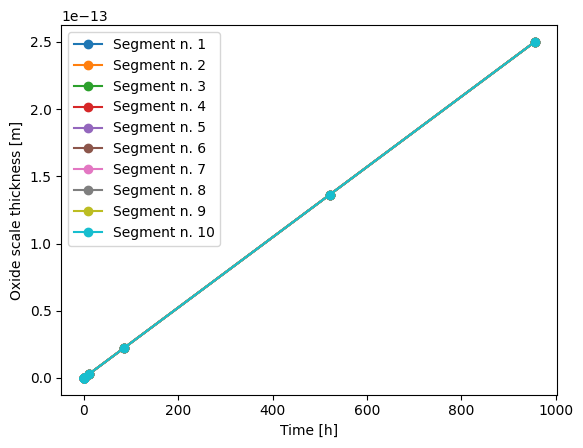

In [16]:
import matplotlib.pyplot as plt
import numpy as np

r_ox = np.transpose(solution_time.y[10 * 2 : 10 * 3])

plt.plot(
    solution_time.t, r_ox, label=[f"Segment n. {i + 1}" for i in range(10)], marker="o"
)
plt.legend()
plt.ylabel("Oxide scale thickness [m]")
plt.xlabel("Time [h]")
plt.show()